<a href="https://www.kaggle.com/code/juansernarivera/g-neros-y-playlists-en-spotify?scriptVersionId=369355197" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Géneros y playlists en Spotify

**Pregunta:** ¿Qué géneros concentran más popularidad en Spotify y qué playlists conviene reforzar?

**Datos:** Spotify Songs, TidyTuesday 2020-01-21, 32,833 canciones.
`track_popularity` es un puntaje de Spotify de 0 a 100, no son reproducciones totales.
`playlist_genre` es el género de la playlist, no necesariamente el género del artista.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-01-21/spotify_songs.csv"
df = pd.read_csv(url)

print(df.shape)
print(df.info())
print(df.isnull().sum())
print("Duplicados por track_id:", df.duplicated(subset="track_id").sum())
print(df.head())


(32833, 23)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32833 entries, 0 to 32832
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   track_id                  32833 non-null  object 
 1   track_name                32828 non-null  object 
 2   track_artist              32828 non-null  object 
 3   track_popularity          32833 non-null  int64  
 4   track_album_id            32833 non-null  object 
 5   track_album_name          32828 non-null  object 
 6   track_album_release_date  32833 non-null  object 
 7   playlist_name             32833 non-null  object 
 8   playlist_id               32833 non-null  object 
 9   playlist_genre            32833 non-null  object 
 10  playlist_subgenre         32833 non-null  object 
 11  danceability              32833 non-null  float64
 12  energy                    32833 non-null  float64
 13  key                       32833 non-null  int64  

In [2]:
# 1. Quitar las 5 filas sin nombre de canción, artista o álbum
df_limpio = df.dropna(subset=["track_name", "track_artist", "track_album_name"])
print("Después de quitar vacíos:", df_limpio.shape)

# 2. Duplicados: la misma canción aparece en varias playlists.
# En df_limpio quedan 4,476 duplicados por track_id, por eso
# se crea una tabla aparte con canciones distintas:
df_unicas = df_limpio.drop_duplicates(subset="track_id")
print("Canciones distintas:", df_unicas.shape)


Después de quitar vacíos: (32828, 23)
Canciones distintas: (28352, 23)


                canciones  popularidad_promedio
playlist_genre                                 
pop                  5507                 47.74
latin                5153                 47.04
rap                  5743                 43.24
rock                 4951                 41.73
r&b                  5431                 41.22
edm                  6043                 34.83


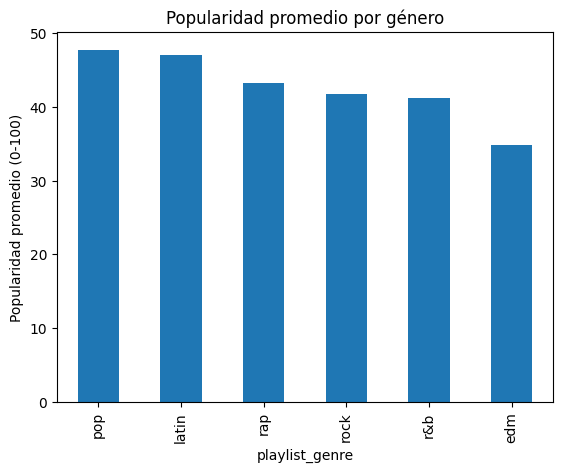

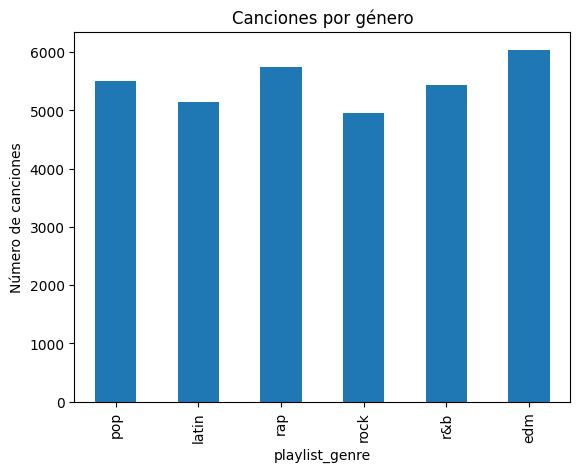

In [3]:
resumen = df_limpio.groupby("playlist_genre").agg(
    canciones=("track_name", "count"),
    popularidad_promedio=("track_popularity", "mean")
).sort_values("popularidad_promedio", ascending=False).round(2)
print(resumen)

resumen["popularidad_promedio"].plot(kind="bar", title="Popularidad promedio por género")
plt.ylabel("Popularidad promedio (0-100)")
plt.show()

resumen["canciones"].plot(kind="bar", title="Canciones por género")
plt.ylabel("Número de canciones")
plt.show()


In [4]:
top_canciones = df_unicas.sort_values("track_popularity", ascending=False).head(10)[
    ["track_name", "track_artist", "playlist_genre", "track_popularity"]
]
print(top_canciones)


                track_name    track_artist playlist_genre  track_popularity
1551          Dance Monkey     Tones and I            pop               100
20092              ROXANNE  Arizona Zervas          latin                99
716        Blinding Lights      The Weeknd            pop                98
5508               The Box     Roddy Ricch            rap                98
1301               Circles     Post Malone            pop                98
711               Memories        Maroon 5            pop                98
687                   Tusa         KAROL G            pop                98
689    everything i wanted   Billie Eilish            pop                97
1302       Don't Start Now        Dua Lipa            pop                97
3155               Falling   Trevor Daniel            pop                97


In [5]:
artistas = df_limpio.groupby(["playlist_genre", "track_artist"]).agg(
    popularidad_promedio=("track_popularity", "mean"),
    canciones_distintas=("track_id", "nunique"),
    apariciones=("track_name", "count")
).reset_index()

artistas = artistas[artistas["canciones_distintas"] >= 3].sort_values(
    ["playlist_genre", "popularidad_promedio"], ascending=[True, False]
)
artistas["popularidad_promedio"] = artistas["popularidad_promedio"].round(2)

print(artistas.groupby("playlist_genre").head(3))


      playlist_genre   track_artist  popularidad_promedio  \
1373             edm         MEDUZA                 85.00   
900              edm   Harry Styles                 84.50   
1284             edm  Lewis Capaldi                 82.33   
2732           latin  Billie Eilish                 91.00   
4561           latin   Travis Scott                 90.00   
4350           latin   Shawn Mendes                 89.00   
6977             pop   Travis Scott                 89.00   
4999             pop  Billie Eilish                 88.08   
6614             pop      Sam Smith                 84.29   
8893             r&b    Roddy Ricch                 88.00   
9331             r&b   XXXTENTACION                 86.33   
9250             r&b   Travis Scott                 86.29   
9856             rap         DaBaby                 86.30   
11034            rap    Roddy Ricch                 86.10   
10236            rap       JACKBOYS                 85.00   
12133           rock    

In [6]:
artistas.groupby("playlist_genre").head(3).to_csv("top_artistas_por_genero.csv", index=False)


## Conclusiones

Pop (47.7) y latin (47.0) tienen la popularidad promedio más alta.
EDM tiene más canciones en el dataset (6,043), pero la popularidad promedio más baja (34.8).

Se quitaron 5 filas sin nombre de canción, artista o álbum.
Hay  4,476 duplicados por track_id porque la misma canción aparece en varias playlists, por eso para el top de canciones se quitaron duplicados y para el top de artistas se cuentan canciones distintas.

Limitación: playlist_genre es el género de la playlist, no del artista. Por eso canciones como "Dance Monkey", "Blinding Lights" y "Memories" aparecen en latin, aunque no son de ese género.

Recomendación: reforzar las playlists de pop y latin, y revisar por qué EDM tiene mucho contenido pero menos popularidad promedio.


In [7]:
df_limpio.to_csv("spotify_limpio.csv", index=False)


In [8]:
cols_audio = ["danceability", "energy", "valence", "tempo", "acousticness", "loudness"]
audio_genero = (
    df_unicas
    .groupby("playlist_genre")[cols_audio]
    .mean()
    .round(2)
    .sort_values("energy", ascending=False)
)
print(audio_genero)


                danceability  energy  valence   tempo  acousticness  loudness
playlist_genre                                                               
edm                     0.66    0.81     0.40  126.33          0.08     -5.49
rock                    0.52    0.73     0.53  125.04          0.15     -7.56
latin                   0.71    0.71     0.61  118.53          0.21     -6.48
pop                     0.64    0.70     0.50  120.96          0.17     -6.38
rap                     0.72    0.65     0.51  120.58          0.20     -7.09
r&b                     0.67    0.59     0.54  113.92          0.26     -8.03


In [9]:
cols_audio = ["danceability", "energy", "valence", "tempo", "acousticness", "loudness"]

# 1. Correlación de cada rasgo con la popularidad
corr_pop = (
    df_unicas[cols_audio + ["track_popularity"]]
    .corr()["track_popularity"]
    .drop("track_popularity")
    .sort_values(ascending=False)
)
print("Correlación con track_popularity:")
print(corr_pop.round(3))

# 2. Top 10% vs. bottom 10% de popularidad
q90 = df_unicas["track_popularity"].quantile(0.90)
q10 = df_unicas["track_popularity"].quantile(0.10)
top = df_unicas[df_unicas["track_popularity"] >= q90]
bottom = df_unicas[df_unicas["track_popularity"] <= q10]
print(f"\nTop 10% (popularidad >= {q90:.0f}): {len(top)} canciones")
print(top[cols_audio].mean().round(2))
print(f"\nBottom 10% (popularidad <= {q10:.0f}): {len(bottom)} canciones")
print(bottom[cols_audio].mean().round(2))

# 3. Correlación por género (para ver si el efecto cambia según el género)
print("\nCorrelación con popularidad, por género:")
print(
    df_unicas.groupby("playlist_genre")[cols_audio + ["track_popularity"]]
    .apply(lambda g: g.corr()["track_popularity"].drop("track_popularity"))
    .round(2)
)


Correlación con track_popularity:
acousticness    0.092
danceability    0.047
loudness        0.037
valence         0.023
tempo           0.004
energy         -0.104
Name: track_popularity, dtype: float64

Top 10% (popularidad >= 69): 2972 canciones
danceability      0.67
energy            0.67
valence           0.53
tempo           121.44
acousticness      0.20
loudness         -6.26
dtype: float64

Bottom 10% (popularidad <= 1): 3162 canciones
danceability      0.64
energy            0.74
valence           0.52
tempo           120.89
acousticness      0.14
loudness         -6.73
dtype: float64

Correlación con popularidad, por género:
track_popularity  danceability  energy  valence  tempo  acousticness  loudness
playlist_genre                                                                
edm                       0.01   -0.07     0.09  -0.02          0.16      0.03
latin                     0.03   -0.09     0.01   0.03          0.12      0.13
pop                       0.09   -0.06 